<a href="https://colab.research.google.com/github/syifaST/simuteh--2330511062-/blob/main/notebook/B4_Penapisan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, sys
REPO = "https://github.com/syifaST/simuteh--2330511062-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

# buat ulang dataset kalau ada folder atau label.csv yang kurang
perlu = ["citra", "bersih", "mask_daun", "mask_bercak"]
if (not all(os.path.exists(f"data/sintetis/{d}") for d in perlu)
        or not os.path.exists("data/sintetis/label.csv")):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Jumlah bersih:", len(os.listdir("../data/sintetis/bersih")))
print("Isi src:", os.listdir("../src"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 442, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 442 (delta 18), reused 1 (delta 1), pack-reused 411 (from 2)
Receiving objects: 100% (442/442), 67.56 MiB | 32.56 MiB/s, done.
Resolving deltas: 100% (111/111), done.
Selesai: 60 citra tersimpan di data/sintetis
Folder kerja: /content/simuteh/notebook
Jumlah citra: 61
Jumlah bersih: 61
Isi src: ['utils_cv.py', 'praproses.py', 'buat_dataset_sintetis.py']


# **4.2**

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from utils_cv import baca, statistik, tampil, kontras_bercak

# Membaca citra dan mask
nama = "teh_041.png"

bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

# Fungsi konvolusi manual
def konvolusi(img, k):  # fungsi dari slide P4
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)

    return np.clip(np.round(out), 0, 255).astype(np.uint8)


# Fungsi konvolusi sejati
def konvolusi_sejati(img, k):  # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))


# Pengujian beberapa kernel
for nm, k in {
    "rerata": np.ones((3, 3)) / 9,
    "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
}.items():

    t0 = time.perf_counter()
    a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0

    beda = np.abs(a.astype(int) - b.astype(int)).max()

    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()

    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.089 s, filter2D=0.01230 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=2.075 s, filter2D=0.00034 s


**4.2 Tabel penapis x derau x PSNR x waktu x KB**

In [3]:
import pandas as pd
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):                  # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):        # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih,
20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0,
                  kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB",
                                     "waktu_ms", "KB"]).round(2)
print(tabel)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  4.45
1   gauss_10  rerata_3    36.90      0.18  7.53
2   gauss_10  rerata_5    37.73      0.20  7.61
3   gauss_10   gauss_5    37.74      0.36  7.74
4   gauss_10  median_3    35.51      0.13  7.42
5   gauss_10  median_5    38.55      1.08  8.55
6   gauss_10  median_9    38.90     23.47  9.33
7   gauss_20     tanpa    22.10      0.00  2.46
8   gauss_20  rerata_3    31.44      0.18  5.70
9   gauss_20  rerata_5    34.56      0.20  6.72
10  gauss_20   gauss_5    32.59      0.39  6.12
11  gauss_20  median_3    29.75      0.13  5.08
12  gauss_20  median_5    33.54      1.06  6.61
13  gauss_20  median_9    35.77     24.49  7.31
14  gauss_40     tanpa    16.35      0.00  1.25
15  gauss_40  rerata_3    25.82      0.26  3.49
16  gauss_40  rerata_5    29.78      0.23  4.89
17  gauss_40   gauss_5    27.04      0.45  3.91
18  gauss_40  median_3    23.82      0.14  2.88
19  gauss_40  median_5    27.84      1.0

# **4.3**

In [4]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:          # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2),
                      kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
print(hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2))

           dI    KB
kernel             
1       31.06  4.99
3       31.49  5.13
5       30.55  5.05
9       24.49  4.67
15       9.48  2.57


          PSNR_dB        waktu_ms              KB      
derau    gauss_20  sp_4% gauss_20  sp_4% gauss_20 sp_4%
penapis                                                
tanpa       22.10  19.32     0.00   0.00     2.46  1.81
rerata_3    31.44  28.54     0.18   0.18     5.70  4.69
rerata_5    34.56  31.83     0.20   0.21     6.72  5.97
gauss_5     32.59  29.65     0.39   0.44     6.12  5.13
median_3    29.75  48.51     0.13   0.14     5.08  9.14
median_5    33.54  45.93     1.06   1.16     6.61  9.05
median_9    35.77  41.72    24.49  22.23     7.31  9.40


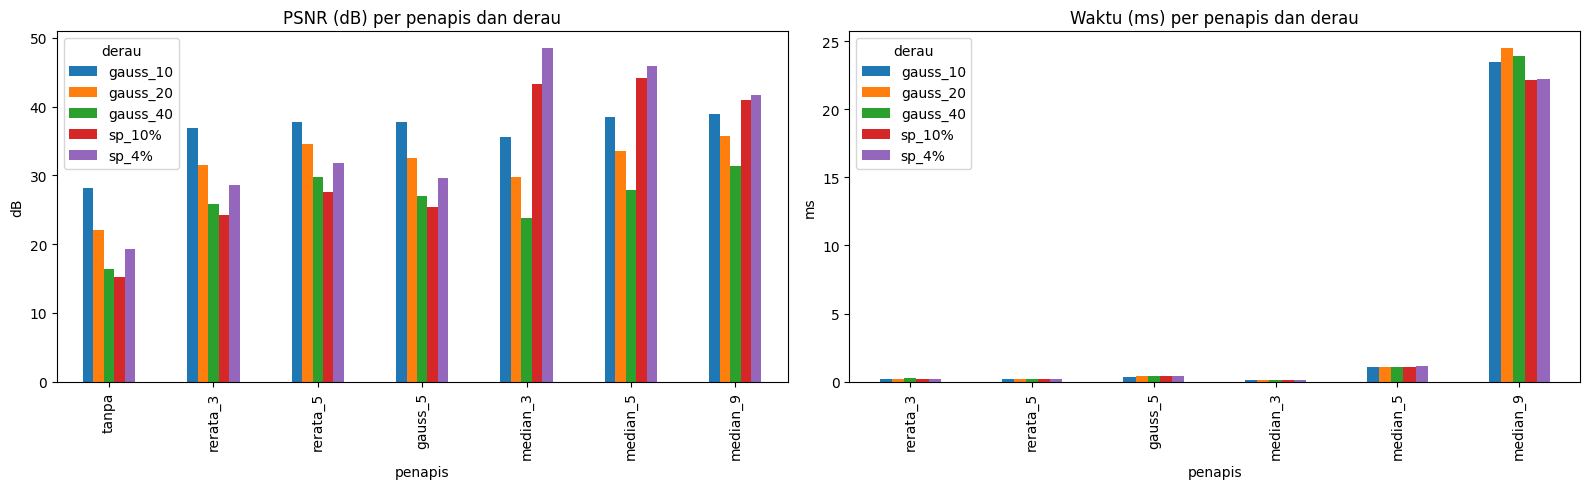

In [5]:
urut = ["tanpa", "rerata_3", "rerata_5", "gauss_5",
        "median_3", "median_5", "median_9"]

# Tabel 11: Gaussian 20 dan garam-merica 4%
t11 = (tabel[tabel.derau.isin(["gauss_20", "sp_4%"])]
       .pivot(index="penapis", columns="derau",
              values=["PSNR_dB", "waktu_ms", "KB"])
       .reindex(urut))
print(t11)

# grafik untuk seluruh hasil
psnr = tabel.pivot(index="penapis", columns="derau", values="PSNR_dB").reindex(urut)
waktu = (tabel[tabel.penapis != "tanpa"]
         .pivot(index="penapis", columns="derau", values="waktu_ms")
         .reindex(urut[1:]))
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
psnr.plot(kind="bar", ax=ax[0], title="PSNR (dB) per penapis dan derau")
waktu.plot(kind="bar", ax=ax[1], title="Waktu (ms) per penapis dan derau")
ax[0].set_ylabel("dB"); ax[1].set_ylabel("ms")
plt.tight_layout()
plt.savefig("../hasil/b4_grafik_psnr_waktu.png")
plt.show()

# **4.4**

           dI    KB
kernel             
1       31.06  4.99
3       31.49  5.13
5       30.55  5.05
9       24.49  4.67
15       9.48  2.57


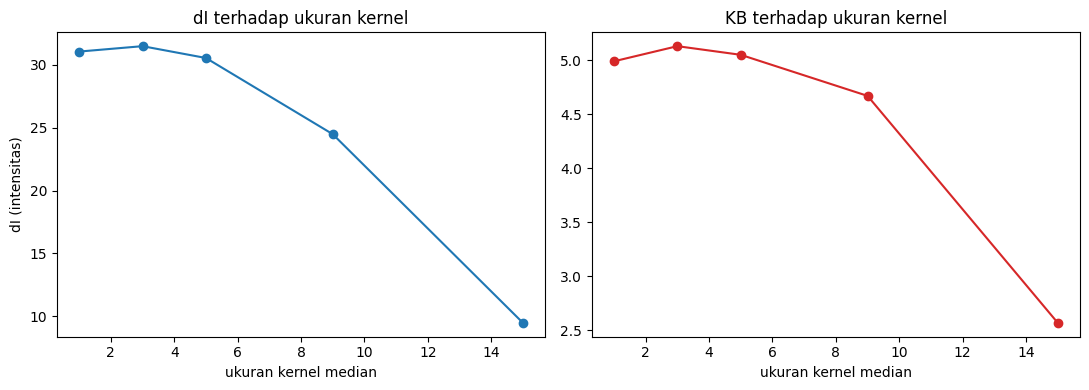

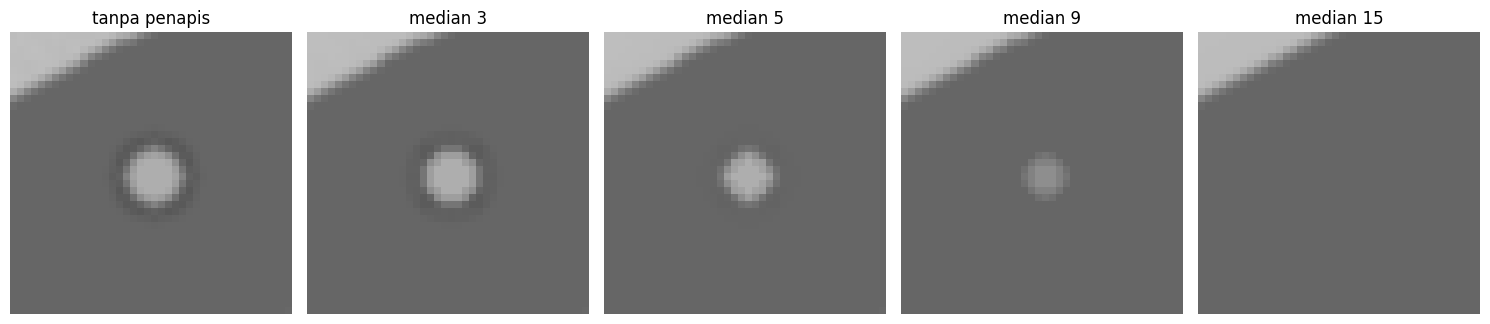

In [7]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:   # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2),
                      kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rata = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print(rata)
rata.to_csv("../hasil/b4_median_kernel.csv")

# grafik dI dan KB terhadap ukuran kernel
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(rata.index, rata.dI, "o-"); ax[0].set_title("dI terhadap ukuran kernel")
ax[0].set_xlabel("ukuran kernel median"); ax[0].set_ylabel("dI (intensitas)")
ax[1].plot(rata.index, rata.KB, "o-", color="tab:red")
ax[1].set_title("KB terhadap ukuran kernel"); ax[1].set_xlabel("ukuran kernel median")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_dI_kernel.png"); plt.show()

# perbesar (crop) satu bercak kecil pada teh_021
nm = "teh_021.png"
g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
n, lab, stat, cent = cv2.connectedComponentsWithStats((mb2 > 0).astype(np.uint8))
idx = 1 + int(np.argmin(stat[1:, cv2.CC_STAT_AREA]))   # bercak terkecil
cx, cy = int(cent[idx][0]), int(cent[idx][1])
y0, x0 = max(cy - 20, 0), max(cx - 20, 0)
fig, ax = plt.subplots(1, 5, figsize=(15, 3.5))
for a, k in zip(ax, [1, 3, 5, 9, 15]):
    out = g if k == 1 else cv2.medianBlur(g, k)
    a.imshow(out[y0:cy + 20, x0:cx + 20], cmap="gray", vmin=0, vmax=255,
             interpolation="nearest")
    a.set_title("tanpa penapis" if k == 1 else f"median {k}"); a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b4_crop_bercak.png"); plt.show()

# **4.5**

In [8]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0   # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))   # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))   # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.34 sigma_latar=8.0 | redam->tajam PSNR=30.20 sigma_latar=8.2
Median: tajam->redam PSNR=30.20 sigma_latar=8.1 | redam->tajam PSNR=31.16 sigma_latar=7.2


# **4.6**

In [9]:
label = pd.read_csv("../data/sintetis/label.csv")
normal = label[label.kondisi_cahaya == "normal"].nama_file   # 12 citra

# penapis pilihan: ganti sesuai hasil Kode 4.2 (gauss_5, median_3, rerata_3)
pilihan = {"gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "rerata_3": lambda x: cv2.blur(x, (3, 3))}
PILIH = "gauss_5"

baris = []
for nm in normal:
    citra = baca(f"../data/sintetis/citra/{nm}")
    bsh = baca(f"../data/sintetis/bersih/{nm}")
    baris.append([nm, round(cv2.PSNR(bsh, citra), 2)] +
                 [round(cv2.PSNR(bsh, f(citra)), 2) for f in pilihan.values()])
t46 = pd.DataFrame(baris, columns=["nama", "PSNR_sebelum"] + list(pilihan))
print(t46)
print(t46.drop(columns="nama").mean().round(2))
t46["PSNR_sesudah_pilihan"] = t46[PILIH]
t46.to_csv("../hasil/b4_psnr_normal.csv", index=False)

           nama  PSNR_sebelum  gauss_5  median_3  rerata_3
0   teh_001.png         31.04    39.43     38.22     38.98
1   teh_006.png         27.76    37.40     35.20     36.56
2   teh_011.png         30.99    39.67     38.18     39.12
3   teh_016.png         27.37    37.10     34.84     36.23
4   teh_021.png         27.48    37.13     34.91     36.28
5   teh_026.png         27.42    37.03     34.88     36.21
6   teh_031.png         27.18    36.93     34.65     36.05
7   teh_036.png         28.61    38.07     36.00     37.29
8   teh_041.png         26.80    36.42     34.25     35.60
9   teh_046.png         27.06    36.64     34.46     35.82
10  teh_051.png         28.92    38.17     36.25     37.46
11  teh_056.png         30.70    38.98     37.84     38.58
PSNR_sebelum    28.44
gauss_5         37.75
median_3        35.81
rerata_3        37.02
dtype: float64
